# Step 7: Group the Dunnhumby households into segments

**What this step does, in plain words.** We have about 2,000 households. We want to sort them into a few groups of *similar shoppers* (for example "deal seekers" or "premium buyers"). The computer does the sorting by itself, from how each household shops. This is called **clustering**.

**Why we need it.** The thesis asks whether different kinds of shoppers switch between products differently when something is removed from the shelf (RQ1). To test that, we first need the kinds of shoppers. This notebook builds them. Step 8 then tests whether they behave differently.

**The plan for this notebook (the picture below shows it):**
1. **Load and prepare** the shopping features.
2. **Explain clustering** with a small picture.
3. **Choose how many groups** using fixed rules (so we cannot cherry-pick).
4. **Fit the final groups** and check they are stable.
5. **Describe the groups** (who are they?).
6. **Check the groups against demographics** we did *not* use.
7. **Check there is enough data** in each group for Step 8.
8. **Save everything.**

*How to read this notebook:* every code cell has comments saying what each line does and why. Every figure has a "How to read it / What we see" note under it.

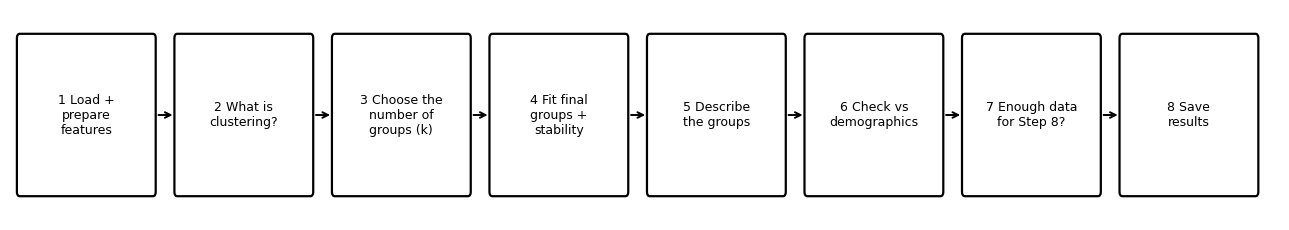

In [1]:
# ------------------------------------------------------------------
# A picture of the plan for this notebook (just a flow chart, no data)
# ------------------------------------------------------------------
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

steps = ["1 Load +\nprepare\nfeatures", "2 What is\nclustering?", "3 Choose the\nnumber of\ngroups (k)", "4 Fit final\ngroups +\nstability",
         "5 Describe\nthe groups", "6 Check vs\ndemographics", "7 Enough data\nfor Step 8?", "8 Save\nresults"]
fig, ax = plt.subplots(figsize=(13, 2.4))
for i, s in enumerate(steps):
    x = i * 1.6
    ax.add_patch(FancyBboxPatch((x, 0.2), 1.35, 1.1, boxstyle="round,pad=0.03", fc="white", ec="black", lw=1.6))   # one box per step
    ax.text(x + 0.675, 0.75, s, ha="center", va="center", fontsize=9)
    if i < len(steps) - 1:
        ax.annotate("", xy=(x + 1.58, 0.75), xytext=(x + 1.38, 0.75), arrowprops=dict(arrowstyle="->", lw=1.4))      # arrow to next step
ax.set_xlim(-0.1, len(steps) * 1.6); ax.set_ylim(0, 1.5); ax.axis("off")
plt.tight_layout(); plt.show()

In [2]:
# ------------------------------------------------------------------
# Imports and settings
# ------------------------------------------------------------------
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats                                    # statistical tests (chi-square)
from sklearn.cluster import KMeans                         # the clustering method we use
from sklearn.mixture import GaussianMixture                # a second clustering method, used as a cross-check
from sklearn.decomposition import PCA                      # squeezes 7 features into 2 so we can draw them
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score, adjusted_rand_score)
warnings.filterwarnings("ignore")

IN  = Path("modelling_inputs_dunnhumby")                   # folder with the tables built in the previous step
OUT = Path("step7_outputs"); (OUT / "figures").mkdir(parents=True, exist_ok=True)   # everything we save goes here

# ---- Settings. They are fixed BEFORE we look at any result, so we cannot tune them to get a nice answer. ----
SEED = 42                    # makes the random parts repeatable: the same seed gives the same answer every run
K_RANGE = range(2, 8)        # we look at 2 to 7 groups
K_CANDIDATES = (3, 4, 5)     # but we only allow 3 to 5 (this is what the proposal says)
MIN_SEG_SHARE = 0.05         # no group may be smaller than 5% of households (too small to model)
N_BOOT = 100                 # how many pairs of random samples we use for the stability check
TIE_MARGIN = 0.03            # two stability scores closer than this count as a tie; the silhouette then decides

# Colours AND marker shapes: shapes are used too, so the plots still work in black and white
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#8a5cc2", "#c9a227"]
MARKERS = ["o", "s", "^", "D", "P"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

## 1. Load the data and look at the features

In [3]:
hh = pd.read_parquet(IN / "hh_segmentation_features.parquet")     # one row per household
scaler = json.load(open(IN / "hh_feature_scaler.json"))           # notes from the previous step about how features were prepared

# 7 features that describe HOW a household shops (we dropped items_per_basket: it is 92% copy of basket_value)
FEATS = scaler["recommended_for_clustering"]
Z = hh[[f + "_z" for f in FEATS]].to_numpy()                      # the standardised version (average 0, spread 1), as a plain table of numbers

print("households:", len(hh))
print("features  :", FEATS)
print("missing values in features:", int(np.isnan(Z).sum()))      # clustering cannot handle gaps, so this must be 0
print("households that also have demographics:", int(hh.has_demo.sum()))

households: 2039
features  : ['basket_value', 'trips_per_shop_week', 'pl_share', 'deal_intensity', 'promo_line_share', 'price_tier', 'mf_hhi']
missing values in features: 0
households that also have demographics: 791


The seven features describe *how* a household shops, not who they are:

| Feature | Meaning |
|---|---|
| basket_value | typical spend per shopping trip (log-scaled) |
| trips_per_shop_week | how often they shop in the weeks they shop (log-scaled) |
| pl_share | share of items that are store brand |
| deal_intensity | how big the discounts they receive are |
| promo_line_share | share of items bought on promotion |
| price_tier | how expensive their usual products are |
| mf_hhi | how concentrated their purchases are on a few manufacturers (brand loyalty) |

**Why features must be built only from the estimation weeks (1 to 75).** If we used the later weeks too, information from the weeks we want to test on would leak into the groups, and the test would be unfair. This was handled in the previous step.

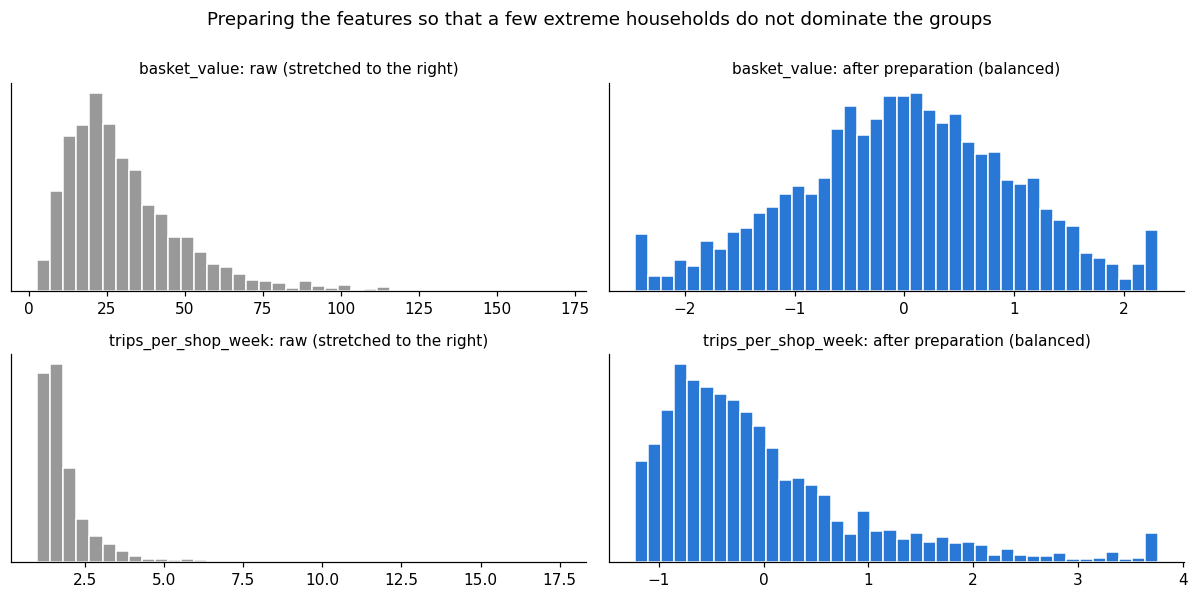

In [4]:
# ---- Why we prepared the features: the before/after of the two most skewed ones ----
fig, axs = plt.subplots(2, 2, figsize=(11, 5.4))
for row, f in enumerate(["basket_value", "trips_per_shop_week"]):
    axs[row, 0].hist(hh[f], bins=40, color="#999999", edgecolor="white")            # raw values: most households small, a few huge
    axs[row, 0].set_title(f"{f}: raw (stretched to the right)", fontsize=10)
    axs[row, 1].hist(hh[f + "_z"], bins=40, color=COLORS[0], edgecolor="white")     # after log + trimming + standardising
    axs[row, 1].set_title(f"{f}: after preparation (balanced)", fontsize=10)
    for a in axs[row]: a.set_yticks([])
fig.suptitle("Preparing the features so that a few extreme households do not dominate the groups", y=1.0)
fig.tight_layout(); fig.savefig(OUT / "figures/s7_01_feature_preparation.png", dpi=150, bbox_inches="tight"); plt.show()

**How to read it.** Left: the raw numbers. A few households spend or shop far more than the rest, which would pull the groups towards them. Right: the same households after taking logs, trimming the most extreme 1% at each end and standardising. The shape is balanced, so every household has a fair say.

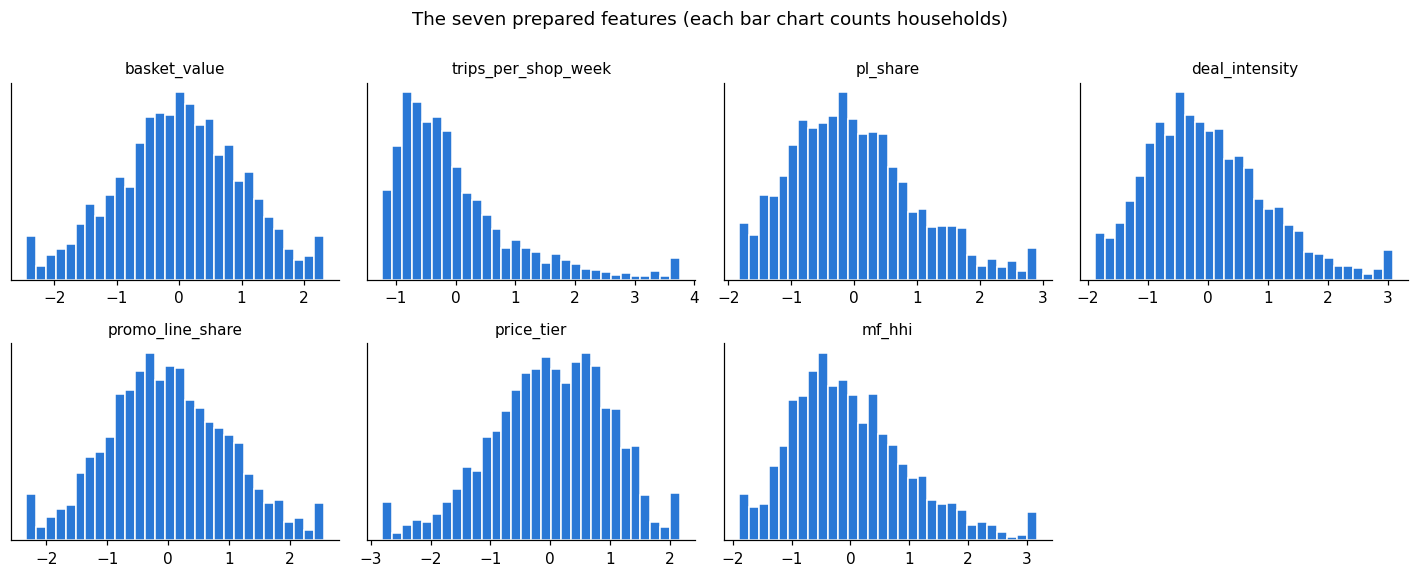

In [5]:
# ---- All seven features after preparation ----
fig, axs = plt.subplots(2, 4, figsize=(13, 5.2))
for ax, f in zip(axs.ravel(), FEATS):
    ax.hist(hh[f + "_z"], bins=30, color=COLORS[0], edgecolor="white")              # one histogram per feature
    ax.set_title(f, fontsize=10); ax.set_yticks([])
axs.ravel()[-1].axis("off")                                                         # 7 features in an 8-panel grid: hide the empty one
fig.suptitle("The seven prepared features (each bar chart counts households)", y=1.0)
fig.tight_layout(); fig.savefig(OUT / "figures/s7_02_features.png", dpi=150, bbox_inches="tight"); plt.show()

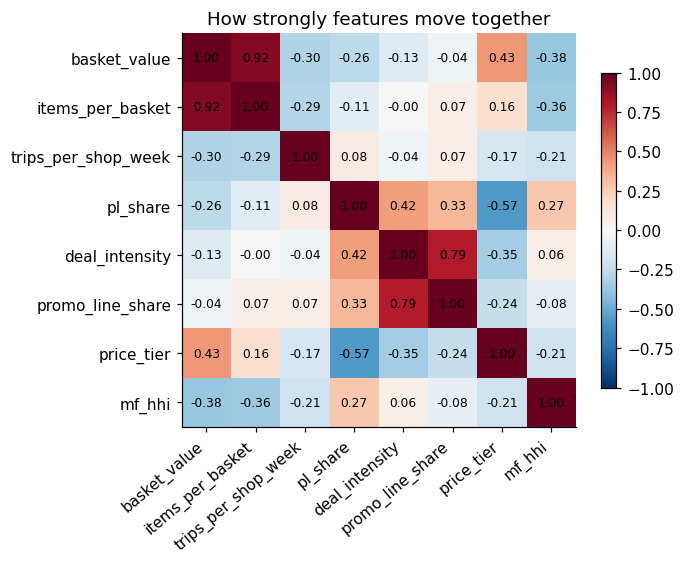

In [6]:
# ---- Are any two features nearly the same thing? (this is why items_per_basket was dropped) ----
corr = pd.read_csv(IN / "hh_feature_correlations.csv", index_col=0)                 # correlations computed in the previous step (8 features)
fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=40, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)): ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)   # write the number in each square
ax.set_title("How strongly features move together"); fig.colorbar(im, ax=ax, shrink=.8)
fig.tight_layout(); fig.savefig(OUT / "figures/s7_03_feature_correlations.png", dpi=150, bbox_inches="tight"); plt.show()

**How to read it.** Each square says how strongly two features rise and fall together (1 = always together, 0 = unrelated, negative = opposite). `basket_value` and `items_per_basket` score 0.92: they are almost the same information. If we kept both, "basket size" would count twice in the clustering, so we kept only `basket_value`. The rest are only moderately related, so each adds something new.

## 2. What is clustering? (a small picture)

**k-means**, the method we use, works like this:
1. Pick *k* starting points (centres) at random.
2. Give each household to its nearest centre.
3. Move each centre to the middle of the households it received.
4. Repeat 2 and 3 until nothing changes.

The picture shows these steps on just **two** features (spend per trip and share of promotion items) so you can watch the groups form. The real analysis uses all seven features at once.

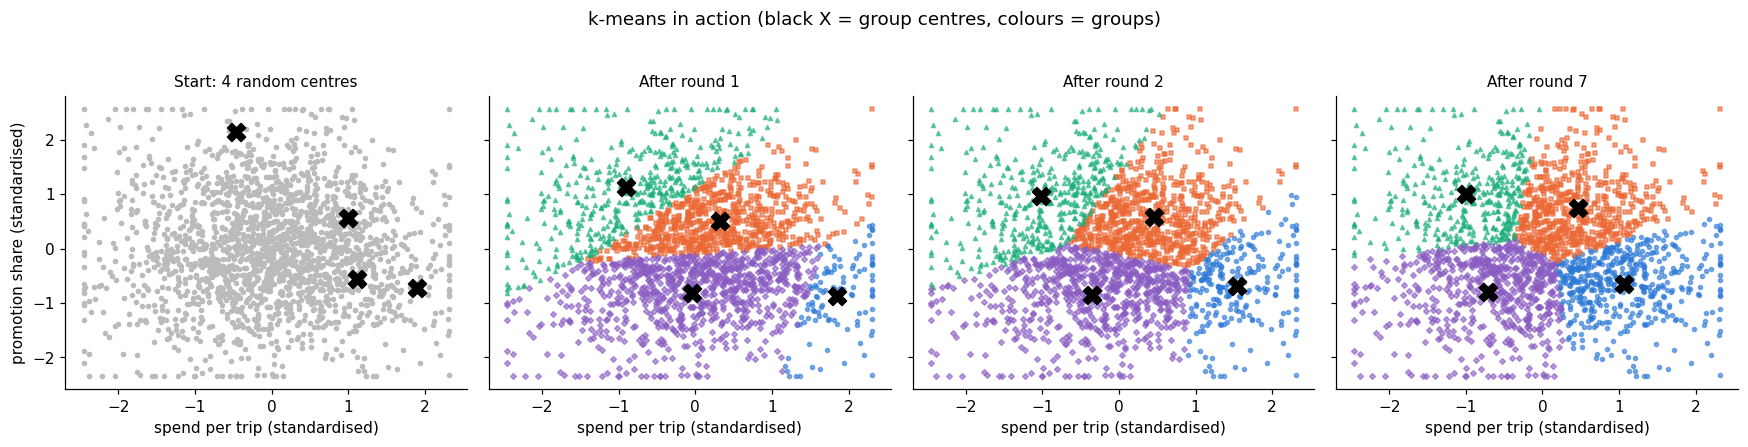

In [7]:
# ---- k-means "by hand" on two features, to show the idea ----
X2 = hh[["basket_value_z", "promo_line_share_z"]].to_numpy()          # only 2 columns so we can draw it flat
r = np.random.RandomState(0)                                          # separate random generator: the demo does not touch our main results
centers = X2[r.choice(len(X2), 4, replace=False)]                     # step 1: 4 random households become the first centres
snapshots = {"Start: 4 random centres": (centers.copy(), None)}
for it in range(1, 8):
    d = ((X2[:, None, :] - centers[None, :, :]) ** 2).sum(2)          # distance from every household to every centre
    lab = d.argmin(1)                                                 # step 2: each household joins its nearest centre
    centers = np.array([X2[lab == k].mean(0) for k in range(4)])      # step 3: move each centre to the middle of its group
    if it in (1, 2, 7): snapshots[f"After round {it}"] = (centers.copy(), lab.copy())
fig, axs = plt.subplots(1, 4, figsize=(16, 3.9), sharex=True, sharey=True)
for ax, (title, (cen, lab)) in zip(axs, snapshots.items()):
    if lab is None: ax.scatter(X2[:, 0], X2[:, 1], s=7, color="#bbbbbb")          # at the start nobody has a group yet
    else:
        for k in range(4): ax.scatter(X2[lab == k, 0], X2[lab == k, 1], s=7, color=COLORS[k], marker=MARKERS[k], alpha=.6)
    ax.scatter(cen[:, 0], cen[:, 1], s=140, color="black", marker="X", zorder=5)  # black X = the centres
    ax.set_title(title, fontsize=10); ax.set_xlabel("spend per trip (standardised)")
axs[0].set_ylabel("promotion share (standardised)")
fig.suptitle("k-means in action (black X = group centres, colours = groups)", y=1.03)
fig.tight_layout(); fig.savefig(OUT / "figures/s7_04_kmeans_demo.png", dpi=150, bbox_inches="tight"); plt.show()

**What we see.** Round by round the black X marks drift to the middle of their households and the colours settle. After a few rounds nothing moves any more. That final state is the answer. Because the starting points are random, the method is run many times in the real analysis and the best result is kept.

## 3. How many groups? (k = the number of groups)

The method needs us to say how many groups to look for. We try 2 to 7 and measure four things:

- **Silhouette** (-1 to 1, higher is better): how well each household fits its own group compared with the next-nearest group.
- **Stability** (0 to 1, higher is better): draw two random 80% samples of households, cluster each one, and compare the answers on the households they share. 1 means identical groups every time. The comparison score is called ARI.
- **Davies-Bouldin** (lower is better): how much the groups overlap.
- **BIC of a mixture model** (lower is better): a model-fit score that punishes needless complexity.

**Decision rule, fixed in advance:** among k = 3, 4, 5, drop any k that has a group smaller than 5% of households; pick the k with the highest stability; if two are within 0.03 of each other, take the one with the higher silhouette.

In [8]:
rng = np.random.default_rng(SEED)            # one random generator for the whole stability loop
n = len(Z)
rows, aris_by_k = [], {}
for k in K_RANGE:
    km = KMeans(k, n_init=20, random_state=SEED).fit(Z)                    # cluster ALL households into k groups (best of 20 starts)
    sizes = np.bincount(km.labels_, minlength=k) / n                       # share of households in each group
    aris = []
    for b in range(N_BOOT):
        a = rng.choice(n, int(0.8 * n), replace=False)                     # random sample 1: 80% of households
        c = rng.choice(n, int(0.8 * n), replace=False)                     # random sample 2: another 80%
        la = KMeans(k, n_init=5, random_state=int(rng.integers(1e9))).fit(Z[a])   # cluster sample 1
        lc = KMeans(k, n_init=5, random_state=int(rng.integers(1e9))).fit(Z[c])   # cluster sample 2
        common = np.intersect1d(a, c)                                      # households that are in both samples
        # ask both clusterings to label those shared households and see how much they agree (ARI)
        aris.append(adjusted_rand_score(la.predict(Z[common]), lc.predict(Z[common])))
    aris_by_k[k] = aris
    gm = GaussianMixture(k, covariance_type="full", n_init=5, random_state=SEED).fit(Z)   # second method, only used for its BIC score
    rows.append(dict(k=k, silhouette=silhouette_score(Z, km.labels_), davies_bouldin=davies_bouldin_score(Z, km.labels_),
                     stability_ari=np.mean(aris), stability_sd=np.std(aris), gmm_bic=gm.bic(Z),
                     inertia=km.inertia_, smallest_group_share=sizes.min()))
sel = pd.DataFrame(rows)
sel.round(3)

,k,silhouette,davies_bouldin,stability_ari,stability_sd,gmm_bic,inertia,smallest_group_share
0,2,0.220,1.655,0.952,0.023,34810.917,10816.268,0.485
1,3,0.196,1.734,0.868,0.089,34536.789,9433.472,0.256
2,4,0.197,1.522,0.901,0.076,34557.051,8359.084,0.135
3,5,0.180,1.559,0.897,0.134,34599.992,7598.466,0.132
4,6,0.161,1.568,0.734,0.134,34665.545,7113.497,0.101
5,7,0.151,1.577,0.724,0.121,34785.445,6744.060,0.080


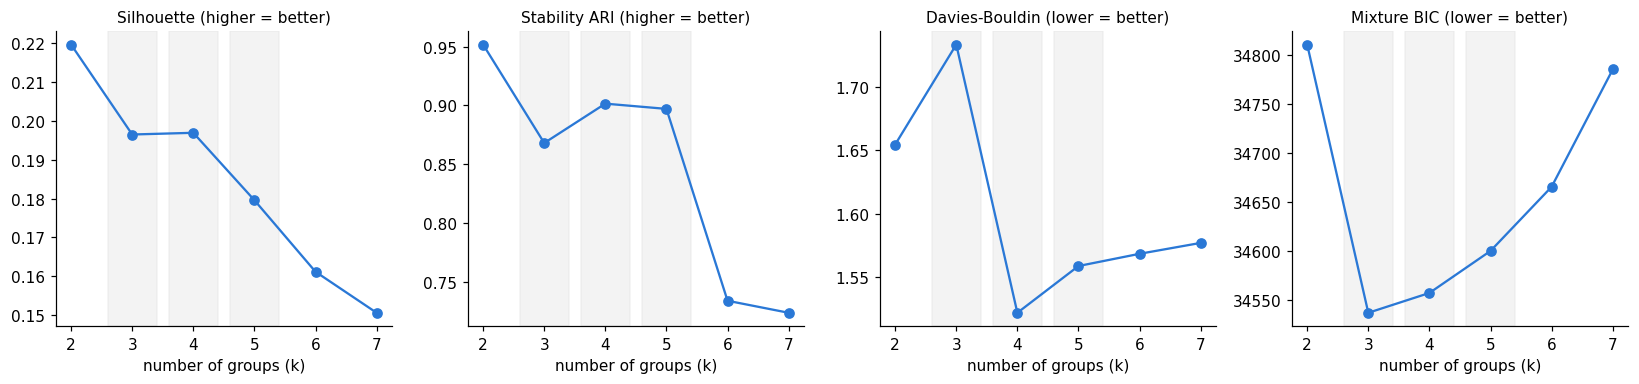

In [9]:
# ---- The four scores side by side (grey bands = the numbers of groups we are allowed to pick) ----
fig, axs = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, col, title in zip(axs, ["silhouette", "stability_ari", "davies_bouldin", "gmm_bic"],
                          ["Silhouette (higher = better)", "Stability ARI (higher = better)", "Davies-Bouldin (lower = better)", "Mixture BIC (lower = better)"]):
    ax.plot(sel.k, sel[col], marker="o", color=COLORS[0]); ax.set_title(title, fontsize=10); ax.set_xlabel("number of groups (k)")
    for k in K_CANDIDATES: ax.axvspan(k - .4, k + .4, color="#dddddd", alpha=.35, zorder=0)
fig.tight_layout(); fig.savefig(OUT / "figures/s7_05_choose_k.png", dpi=150, bbox_inches="tight"); plt.show()

**How to read it.** Each panel is one score. The grey bands mark 3, 4 and 5, the only choices allowed. No single k wins every panel, which is normal. Two things matter: scores for k = 4 and 5 are close, and stability drops sharply after 5 (the groups stop being repeatable).

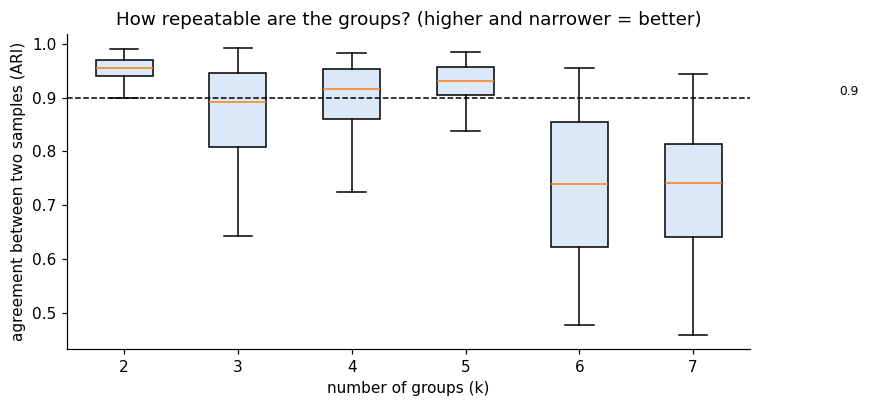

In [10]:
# ---- Stability in detail: each box shows the 100 agreement scores for one k ----
fig, ax = plt.subplots(figsize=(8, 3.8))
bp = ax.boxplot([aris_by_k[k] for k in K_RANGE], tick_labels=list(K_RANGE), patch_artist=True, showfliers=False)
for patch in bp["boxes"]: patch.set_facecolor("#dbe8f8")
ax.axhline(0.9, color="black", ls="--", lw=1); ax.text(7.45, 0.905, "0.9", fontsize=8, ha="right")
ax.set_xlabel("number of groups (k)"); ax.set_ylabel("agreement between two samples (ARI)")
ax.set_title("How repeatable are the groups? (higher and narrower = better)")
fig.tight_layout(); fig.savefig(OUT / "figures/s7_06_stability.png", dpi=150, bbox_inches="tight"); plt.show()

**How to read it.** Each box covers 100 repeats of "cluster two different random samples and compare". High boxes mean the same groups keep appearing. k = 2 is the most repeatable (two groups is easy), k = 4 and 5 are still around 0.9, and from k = 6 the groups start to change from sample to sample. So choosing 4 or 5 is safe, 6 or more is not.

In [11]:
# ---- Apply the decision rule from above (automatically, no human judgement) ----
cand = sel[sel.k.isin(K_CANDIDATES) & (sel.smallest_group_share >= MIN_SEG_SHARE)].copy()     # allowed k with big-enough groups
best_stab = cand.stability_ari.max()
tied = cand[cand.stability_ari >= best_stab - TIE_MARGIN]                                    # all k whose stability is (almost) the best
K = int(tied.sort_values("silhouette", ascending=False).iloc[0].k)                           # among them take the best silhouette
print("allowed after the size rule:", cand.k.tolist())
print("tied on stability          :", tied.k.tolist())
print("=> chosen number of groups : k =", K)
cand.round(3)

allowed after the size rule: [3, 4, 5]
tied on stability          : [4, 5]
=> chosen number of groups : k = 4


,k,silhouette,davies_bouldin,stability_ari,stability_sd,gmm_bic,inertia,smallest_group_share
1,3,0.196,1.734,0.868,0.089,34536.789,9433.472,0.256
2,4,0.197,1.522,0.901,0.076,34557.051,8359.084,0.135
3,5,0.180,1.559,0.897,0.134,34599.992,7598.466,0.132


## 4. Fit the final groups and test them

Now we run k-means once more, carefully (100 random starts), to get the final groups. Then we test them two ways:

1. **Same method, different random starts** (20 times): do we always get the same groups?
2. **A different method (Gaussian mixture)**: does it find the same groups?

In [12]:
km = KMeans(K, n_init=100, random_state=SEED).fit(Z)                      # final clustering: best of 100 random starts
order = np.argsort(-np.bincount(km.labels_))                              # sort the groups from largest to smallest ...
remap = {old: new + 1 for new, old in enumerate(order)}                   # ... so Segment 1 is the biggest, Segment 2 the next, etc.
seg = np.array([remap[l] for l in km.labels_])                            # the final segment number of each household (1..K)
centers = km.cluster_centers_[order]                                      # the centre (average household) of each group, in the same order

# Test 1: run k-means 20 times from a single random start each, and compare every run with the first
runs = [KMeans(K, n_init=1, random_state=s).fit(Z).labels_ for s in range(20)]
ari_seeds = np.mean([adjusted_rand_score(runs[0], r) for r in runs[1:]])

# Test 2: a different method. k-means draws hard borders; a Gaussian mixture allows overlapping, oval-shaped groups
gm = GaussianMixture(K, covariance_type="full", n_init=10, random_state=SEED).fit(Z)
ari_gmm = adjusted_rand_score(seg, gm.predict(Z))

print(f"agreement across 20 random starts (ARI, 1 = identical): {ari_seeds:.2f}")
print(f"agreement k-means vs Gaussian mixture (ARI)           : {ari_gmm:.2f}")
print("group sizes:", pd.Series(seg).value_counts().sort_index().to_dict())
hh["segment"] = seg

agreement across 20 random starts (ARI, 1 = identical): 0.86
agreement k-means vs Gaussian mixture (ARI)           : 0.34
group sizes: {1: 791, 2: 590, 3: 381, 4: 277}


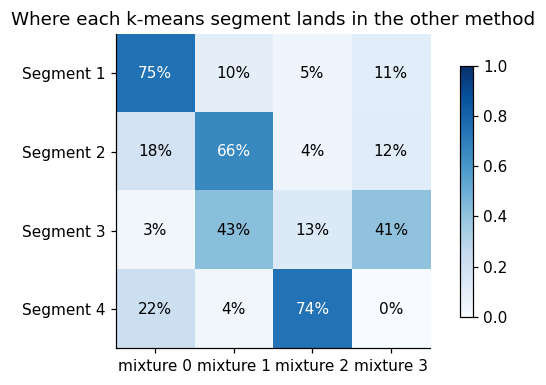

In [13]:
# ---- Do the two methods agree? Rows = k-means segment, columns = mixture-model component; each row adds to 100% ----
gm_lab = gm.predict(Z)
ct = pd.crosstab(seg, gm_lab, normalize="index")
fig, ax = plt.subplots(figsize=(5.8, 3.6))
im = ax.imshow(ct.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels([f"mixture {c}" for c in ct.columns])
ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels([f"Segment {s}" for s in ct.index])
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]): ax.text(j, i, f"{ct.values[i, j]:.0%}", ha="center", va="center", color="white" if ct.values[i, j] > .5 else "black")
ax.set_title("Where each k-means segment lands in the other method"); fig.colorbar(im, ax=ax, shrink=.8)
fig.tight_layout(); fig.savefig(OUT / "figures/s7_07_method_agreement.png", dpi=150, bbox_inches="tight"); plt.show()

**How to read it.** If both methods found exactly the same groups, every row would have one dark square near 100%. Segments 1, 2 and 4 mostly land in a single mixture component (75%, 66% and 74%), so the second method recognises them fairly well. **Segment 3 is split almost evenly between two components (43% and 41%)**, so it is the least clear-cut group. The overall agreement score is only 0.34, which tells us the groups are **not sharply separated**: shoppers vary smoothly from one style to another (the 2-D picture below shows this too). The groups are useful slices of that spread, but the thesis should not claim they are natural, sharply different customer types.

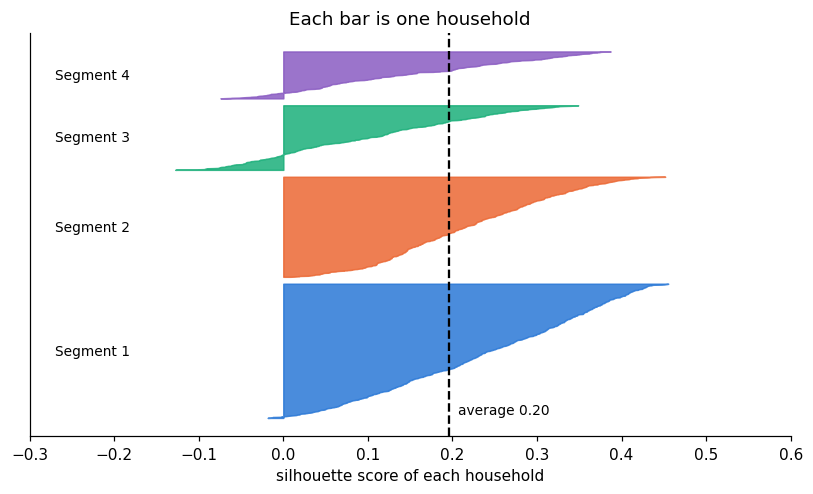

In [14]:
# ---- How well does each household fit its own group? (silhouette of every single household) ----
sil = silhouette_samples(Z, seg)                      # one score per household: 1 = fits perfectly, 0 = on the border, negative = may belong elsewhere
fig, ax = plt.subplots(figsize=(7.5, 4.6))
y0 = 0
for s in range(1, K + 1):
    v = np.sort(sil[seg == s])                        # sort inside the group so the bars form a smooth shape
    ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=COLORS[s - 1], alpha=.85)
    ax.text(-0.27, y0 + len(v) / 2, f"Segment {s}", va="center", fontsize=9)
    y0 += len(v) + 40
ax.axvline(sil.mean(), color="black", ls="--"); ax.text(sil.mean() + .01, 20, f"average {sil.mean():.2f}", fontsize=9)
ax.set_yticks([]); ax.set_xlabel("silhouette score of each household"); ax.set_xlim(-0.3, 0.6)
ax.set_title("Each bar is one household")
fig.tight_layout(); fig.savefig(OUT / "figures/s7_08_silhouette_by_household.png", dpi=150, bbox_inches="tight"); plt.show()

**How to read it.** Each thin bar is one household. Bars to the right mean the household clearly belongs in its group; bars at or left of zero mean it sits on a border or may fit another group better. The average is about 0.2, which is low, so many households sit near borders. Segment 3 has the longest tail below zero, matching the previous picture (it is the least clear-cut group). Low scores do not mean the groups are useless; Step 8 will test whether they predict choices better than random groups.

## 5. What does each group look like?

In [15]:
# ---- Average of each feature in each group, in the original (easy-to-read) units ----
prof = hh.groupby("segment").agg(households=("household_key", "size"), **{f: (f, "mean") for f in FEATS}).round(3)
prof.insert(1, "share_of_households", (prof.households / len(hh)).round(3))
prof

,households,share_of_households,basket_value,trips_per_shop_week,pl_share,deal_intensity,promo_line_share,price_tier,mf_hhi
segment,,,,,,,,,
1,791,0.388,38.955,1.661,0.161,0.123,0.417,0.599,0.562
2,590,0.289,34.691,1.598,0.242,0.206,0.570,0.545,0.549
3,381,0.187,16.543,1.729,0.338,0.183,0.492,0.468,0.662
4,277,0.136,19.449,3.857,0.253,0.161,0.510,0.507,0.526


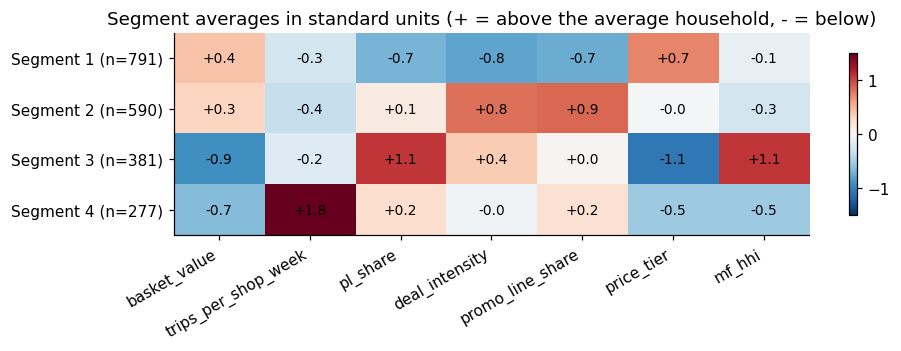

In [16]:
# ---- Heat map: how far above (red) or below (blue) the average household is each group on each feature ----
cz = pd.DataFrame(centers, columns=FEATS, index=range(1, K + 1))       # group averages in "standard units"
fig, ax = plt.subplots(figsize=(9, 0.9 + 0.6 * K))
im = ax.imshow(cz.values, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(FEATS))); ax.set_xticklabels(FEATS, rotation=30, ha="right")
ax.set_yticks(range(K)); ax.set_yticklabels([f"Segment {i} (n={int((seg==i).sum())})" for i in range(1, K + 1)])
for i in range(K):
    for j in range(len(FEATS)): ax.text(j, i, f"{cz.values[i, j]:+.1f}", ha="center", va="center", fontsize=9)   # write the number in each square
ax.set_title("Segment averages in standard units (+ = above the average household, - = below)")
fig.colorbar(im, ax=ax, shrink=.8); fig.tight_layout(); fig.savefig(OUT / "figures/s7_09_segment_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

**How to read it.** A number of +1 means "one standard step above the typical household"; -1 means one step below. Reading across a row gives that segment's personality:

- **Segment 1** (largest): higher price level, far lower store-brand share, deal depth and promotion share. *Premium, full-price buyers.*
- **Segment 2:** much more promotion and deeper discounts than average. *Deal seekers.*
- **Segment 3:** small baskets, cheap products, lots of store brand, buys from few manufacturers. *Budget store-brand buyers.*
- **Segment 4:** shops very often (+1.8) but spends little per trip. *Frequent small-basket shoppers.*

These names are suggestions; change them to what you prefer.

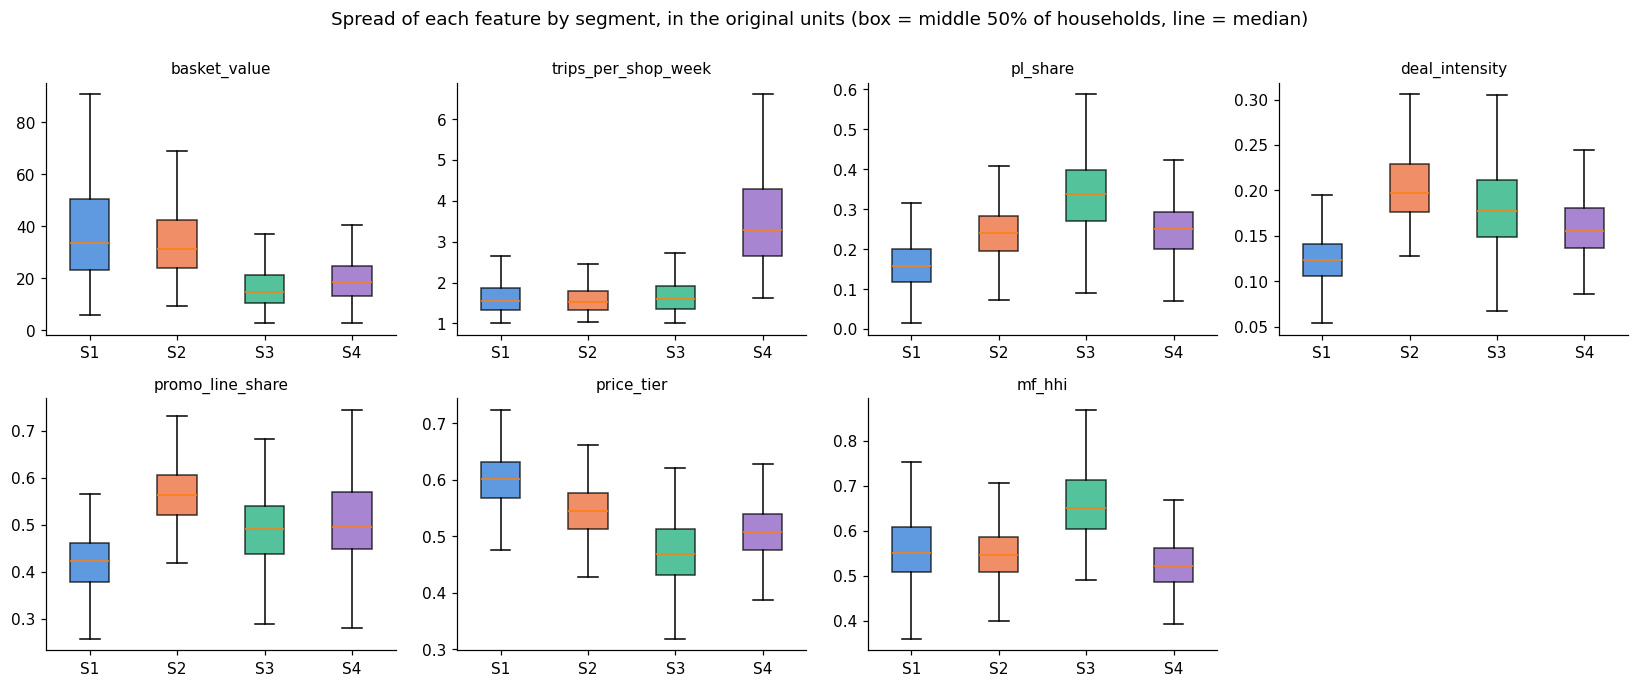

In [17]:
# ---- The full spread of each feature inside each segment (not only the average) ----
fig, axs = plt.subplots(2, 4, figsize=(15, 6.2))
for ax, f in zip(axs.ravel(), FEATS):
    data = [hh.loc[hh.segment == s, f] for s in range(1, K + 1)]
    bp = ax.boxplot(data, tick_labels=[f"S{s}" for s in range(1, K + 1)], patch_artist=True, showfliers=False)   # box = middle half of households
    for patch, col in zip(bp["boxes"], COLORS): patch.set_facecolor(col); patch.set_alpha(.75)
    ax.set_title(f, fontsize=10)
axs.ravel()[-1].axis("off")
fig.suptitle("Spread of each feature by segment, in the original units (box = middle 50% of households, line = median)", y=1.0)
fig.tight_layout(); fig.savefig(OUT / "figures/s7_10_feature_spread_by_segment.png", dpi=150, bbox_inches="tight"); plt.show()

**How to read it.** Each box covers the middle half of a segment's households; the line inside is the median. Boxes that sit clearly apart (for example `promo_line_share` for S2, `trips_per_shop_week` for S4, `pl_share` for S3) are the features that define a segment. Boxes that overlap heavily mean the segments share that feature. Overlap everywhere is another sign of fuzzy groups.

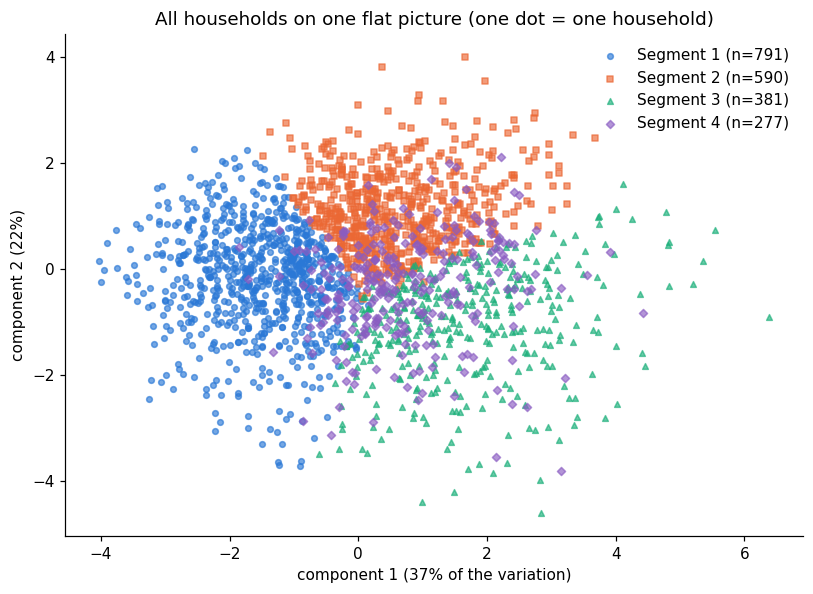

In [18]:
# ---- A flat 2-D picture of all households (PCA squeezes 7 features into the 2 that keep the most information) ----
pca = PCA(2, random_state=SEED).fit(Z); P = pca.transform(Z)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for s in range(1, K + 1):
    m = seg == s
    ax.scatter(P[m, 0], P[m, 1], s=14, alpha=.65, color=COLORS[s - 1], marker=MARKERS[s - 1], label=f"Segment {s} (n={m.sum()})")
ax.set_xlabel(f"component 1 ({pca.explained_variance_ratio_[0]:.0%} of the variation)"); ax.set_ylabel(f"component 2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("All households on one flat picture (one dot = one household)"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(OUT / "figures/s7_11_pca.png", dpi=150, bbox_inches="tight"); plt.show()

**How to read it.** Each dot is a household; nearby dots shop alike. The segments occupy different regions (Segment 1 on the left, Segment 3 lower right, Segment 2 upper middle) but their edges blend into each other, with Segment 4 spread through the middle. There is no empty gap between groups. That is the same "fuzzy groups" finding as before, now visible.

In [19]:
# ---- A "typical household" for each segment: the real household closest to the group centre ----
dist = ((Z[:, None, :] - centers[None, :, :]) ** 2).sum(2)                # distance from every household to every group centre
typical = [hh.iloc[np.argmin(np.where(seg == s, dist[:, s - 1], np.inf))] for s in range(1, K + 1)]
pd.DataFrame([{"segment": int(t.segment), "household_key": int(t.household_key), **{f: round(float(t[f]), 2) for f in FEATS}} for t in typical])

,segment,household_key,basket_value,trips_per_shop_week,pl_share,deal_intensity,promo_line_share,price_tier,mf_hhi
0,1,107,30.47,1.53,0.15,0.13,0.43,0.61,0.57
1,2,170,39.03,1.48,0.24,0.20,0.53,0.55,0.56
2,3,1659,18.71,1.74,0.37,0.19,0.49,0.49,0.65
3,4,1917,22.30,3.03,0.25,0.15,0.52,0.52,0.53


**Tentative names.** The next cell writes a short description of each segment from its numbers: it lists the features that are clearly above or below average (more than half a standard step). Treat the automatic labels as a draft for naming the segments in the thesis.

In [20]:
NICE = {"basket_value": "spend per trip", "trips_per_shop_week": "trip frequency", "pl_share": "store-brand share", "deal_intensity": "discount depth",
        "promo_line_share": "promotion share", "price_tier": "price level", "mf_hhi": "brand concentration"}   # plain-English feature names
def describe(row):
    hi = [NICE[f] for f in FEATS if row[f] >= .5]            # features at least half a step ABOVE average
    lo = [NICE[f] for f in FEATS if row[f] <= -.5]           # features at least half a step BELOW average
    return ("high " + ", ".join(hi) if hi else "") + ("; " if hi and lo else "") + ("low " + ", ".join(lo) if lo else "") or "close to average on everything"
labels = {s: describe(cz.loc[s]) for s in cz.index}
hh["segment_description"] = hh.segment.map(labels)
pd.Series(labels, name="description").to_frame()

,description
1,"high price level; low store-brand share, disco..."
2,"high discount depth, promotion share"
3,"high store-brand share, brand concentration; l..."
4,"high trip frequency; low spend per trip, price..."


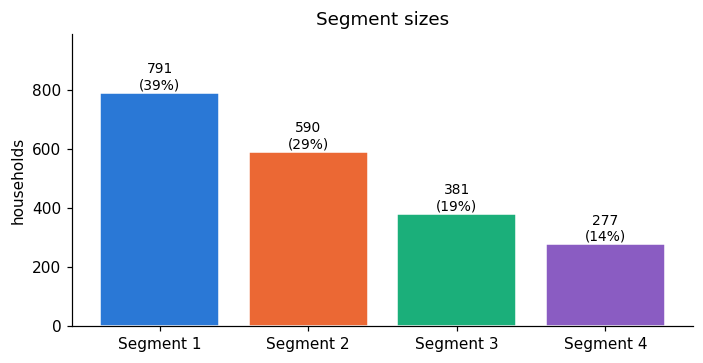

In [21]:
# ---- How big is each segment? ----
fig, ax = plt.subplots(figsize=(6.5, 3.4))
sz = pd.Series(seg).value_counts().sort_index()
ax.bar([f"Segment {s}" for s in sz.index], sz.values, color=COLORS[:K], edgecolor="white")
for i, v in enumerate(sz.values): ax.text(i, v + 12, f"{v}\n({v / len(hh):.0%})", ha="center", fontsize=9)     # label with count and percentage
ax.set_ylabel("households"); ax.set_ylim(0, sz.max() * 1.25); ax.set_title("Segment sizes")
fig.tight_layout(); fig.savefig(OUT / "figures/s7_12_segment_sizes.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Do the groups match something we did NOT use? (demographics)

The groups were built from shopping behaviour only. Demographics (age, income, household type, children) are known for about 790 of these households. If the groups also differ in demographics, that is *independent* evidence they mean something. If they do not, that is also acceptable: for substitution what matters is how people shop, and the thesis should say so.

We test each demographic with a **chi-square test** (are the segments' mixes different by more than chance?). **Cramér's V** says how big the difference is: 0 means none, about 0.1 small, 0.2 or more noticeable.

In [22]:
d = hh[hh.has_demo].copy()                                     # only households that have demographic information

def lower(s):                                                  # turn an income label like "35-49K" into its lower number (35)
    try: return float(str(s).replace("K", "").replace("+", "").replace("Under ", "0").split("-")[0])
    except Exception: return np.nan

# group the detailed categories into a few broad bands (so each cell has enough households to test)
d["income_band"] = pd.cut(d.income_desc.map(lower), [-1, 34, 74, 1e9], labels=["under 35K", "35-74K", "75K+"])
d["age_band"] = pd.cut(d.age_desc.str.extract(r"(\d+)")[0].astype(float), [0, 34, 54, 200], labels=["19-34", "35-54", "55+"])
d["has_kids"] = np.where(d.kid_category_desc.fillna("None/Unknown").eq("None/Unknown"), "no / unknown", "children")
d["hh_type"] = d.hh_comp_desc.fillna("Unknown")

res = []
for col in ["income_band", "age_band", "has_kids", "hh_type"]:
    ct = pd.crosstab(d.segment, d[col])                        # count of households for every segment x category
    chi2, p, dof, exp = stats.chi2_contingency(ct)             # is the pattern different from what luck alone would give?
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))     # Cramer's V = effect size
    res.append(dict(variable=col, households=int(ct.values.sum()), chi2=round(chi2, 1), p_value=round(p, 4), cramers_v=round(v, 3),
                    small_expected_cells=int((exp < 5).sum())))     # warns if some cells are too small for the test to be trusted
demo_tests = pd.DataFrame(res); demo_tests

,variable,households,chi2,p_value,cramers_v,small_expected_cells
0,income_band,791,79.5,0.0000,0.224,0
1,age_band,791,6.9,0.3302,0.066,0
2,has_kids,791,18.5,0.0003,0.153,0
3,hh_type,791,28.0,0.0219,0.109,1


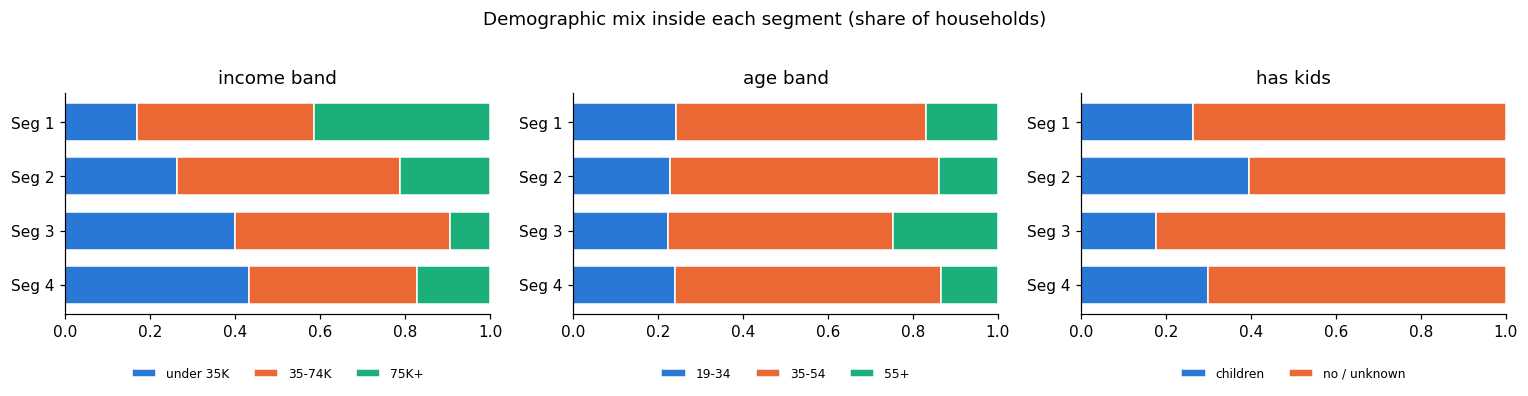

In [23]:
# ---- Mix inside each segment (bars add to 100%) ----
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axs, ["income_band", "age_band", "has_kids"]):
    t = pd.crosstab(d.segment, d[col], normalize="index")      # share within each segment
    bottom = np.zeros(len(t))
    for i, c in enumerate(t.columns):
        ax.barh(t.index, t[c], left=bottom, label=str(c), color=COLORS[i], edgecolor="white", height=.7); bottom += t[c].values
    ax.set_yticks(t.index); ax.set_yticklabels([f"Seg {i}" for i in t.index]); ax.invert_yaxis(); ax.set_xlim(0, 1)
    ax.set_title(col.replace("_", " ")); ax.legend(frameon=False, fontsize=8, loc="lower center", bbox_to_anchor=(.5, -.35), ncol=3)
fig.suptitle("Demographic mix inside each segment (share of households)", y=1.02)
fig.tight_layout(); fig.savefig(OUT / "figures/s7_13_demographics.png", dpi=150, bbox_inches="tight"); plt.show()

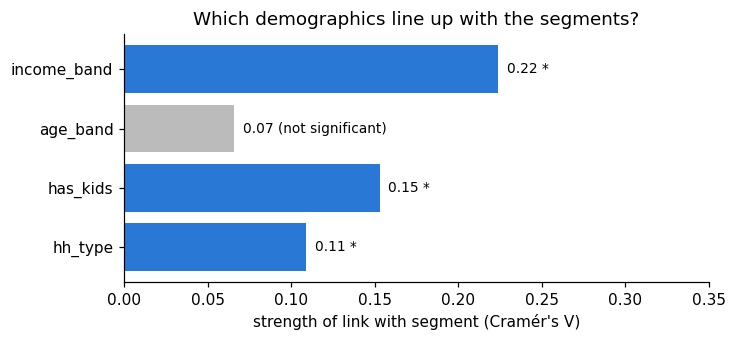

In [24]:
# ---- How strong is each link? (Cramer's V; stars mark links that are statistically significant at 5%) ----
fig, ax = plt.subplots(figsize=(6.8, 3.2))
vals = demo_tests.set_index("variable").cramers_v; ps = demo_tests.set_index("variable").p_value
ax.barh(vals.index, vals.values, color=[COLORS[0] if ps[i] < .05 else "#bbbbbb" for i in vals.index])   # blue = significant, grey = not
for i, (name, v) in enumerate(vals.items()): ax.text(v + .005, i, f"{v:.2f}" + (" *" if ps[name] < .05 else " (not significant)"), va="center", fontsize=9)
ax.set_xlim(0, .35); ax.invert_yaxis(); ax.set_xlabel("strength of link with segment (Cramér's V)")
ax.set_title("Which demographics line up with the segments?")
fig.tight_layout(); fig.savefig(OUT / "figures/s7_14_demographic_links.png", dpi=150, bbox_inches="tight"); plt.show()

**What we see.** Income lines up with the segments most clearly: Segments 3 and 4 have more low-income households and Segment 1 more high-income ones. Having children and household type link more weakly. Age shows no link. This is good, independent support that the segments carry meaning: the groups built only from shopping behaviour also differ in income. It covers only the 790 households that have demographics, so it is supporting evidence, not proof.

## 7. Is there enough data in each group for Step 8?

The choice models in Step 8 learn from category purchases (cereal, soup). A group with very few purchases cannot support its own model. Households that did not qualify for segmentation (too few trips to describe their shopping) stay **unassigned**; they are shown too.

In [25]:
rows = []
segmap = hh.set_index("household_key").segment                                   # household -> segment
for cat in ["cereal", "soup"]:
    o = pd.read_parquet(IN / f"choice_occasions_{cat}.parquet")                  # one row per household-week with a basket
    o["segment"] = o.household_key.map(segmap).fillna(0).astype(int)             # 0 means "not assigned to a segment"
    for (s, split), g in o.groupby(["segment", "split"]):
        rows.append(dict(category=cat, segment=s if s else "unassigned", period="estimation" if split == "est" else "holdout",
                         household_weeks=len(g), category_purchases=int(g.bought.sum())))     # "bought" = 1 when the household bought from the category that week
feas = pd.DataFrame(rows)
feas.pivot_table(index="segment", columns=["category", "period"], values="category_purchases", aggfunc="sum")

category       cereal               soup        
period     estimation holdout estimation holdout
segment                                         
1                6533    2585       4050    2286
2                4240    1911       2940    1606
3                1795     809       1126     591
4                3336    1219       1830     886
unassigned        493     361        310     292

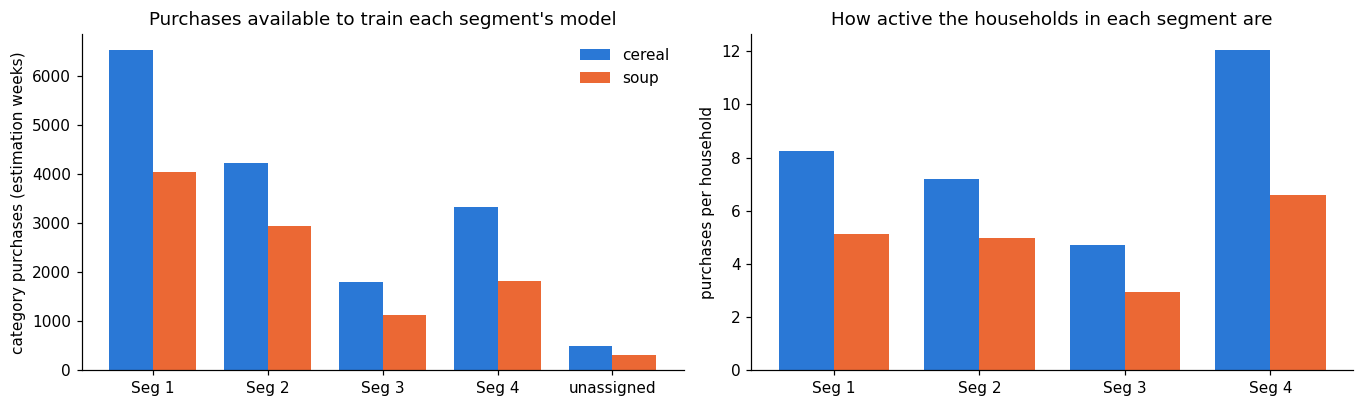

,category,segment,household_weeks,category_purchases,share_of_purchases,purchases_per_household
0,cereal,unassigned,4267,493,0.030,NaN
2,cereal,1,32096,6533,0.398,8.26
4,cereal,2,22692,4240,0.259,7.19
6,cereal,3,14062,1795,0.109,4.71
8,cereal,4,14782,3336,0.203,12.04
10,soup,unassigned,4267,310,0.030,NaN
12,soup,1,32096,4050,0.395,5.12
14,soup,2,22692,2940,0.287,4.98
16,soup,3,14062,1126,0.110,2.96
18,soup,4,14782,1830,0.178,6.61


In [26]:
# ---- Purchases available to train each segment's model, and purchases per household ----
est = feas[feas.period == "estimation"].copy()
tot = est.groupby("category").category_purchases.transform("sum")
est["share_of_purchases"] = (est.category_purchases / tot).round(3)
est["purchases_per_household"] = est.apply(lambda r: r.category_purchases / max((hh.segment == r.segment).sum(), 1) if r.segment != "unassigned" else np.nan, axis=1).round(2)

fig, axs = plt.subplots(1, 2, figsize=(12.5, 3.8))
x = np.arange(K + 1); labs = [f"Seg {i}" for i in range(1, K + 1)] + ["unassigned"]
for j, cat in enumerate(["cereal", "soup"]):
    v = [est[(est.category == cat) & (est.segment == (i if i else "unassigned"))].category_purchases.sum() for i in list(range(1, K + 1)) + [0]]
    axs[0].bar(x + (j - .5) * .38, v, .38, color=COLORS[j], label=cat)
axs[0].set_xticks(x); axs[0].set_xticklabels(labs); axs[0].set_ylabel("category purchases (estimation weeks)"); axs[0].legend(frameon=False)
axs[0].set_title("Purchases available to train each segment's model")
for j, cat in enumerate(["cereal", "soup"]):
    v = [est[(est.category == cat) & (est.segment == i)].purchases_per_household.sum() for i in range(1, K + 1)]
    axs[1].bar(np.arange(K) + (j - .5) * .38, v, .38, color=COLORS[j], label=cat)
axs[1].set_xticks(range(K)); axs[1].set_xticklabels([f"Seg {i}" for i in range(1, K + 1)]); axs[1].set_ylabel("purchases per household")
axs[1].set_title("How active the households in each segment are")
fig.tight_layout(); fig.savefig(OUT / "figures/s7_15_purchases_per_segment.png", dpi=150, bbox_inches="tight"); plt.show()
est[["category", "segment", "household_weeks", "category_purchases", "share_of_purchases", "purchases_per_household"]]

**What we see.** Segment 1 has the most purchases because it is the largest. **Segment 3 is thin, especially for soup** (about 1,100 purchases in the estimation weeks): a model for that group alone would be unreliable if every product had its own preference number. In Step 8 we therefore describe products by their features (price, promotion, brand, size) and let segments share parts of the model. The right panel shows Segment 4 is the most active per household (frequent shoppers), and Segment 3 the least for soup.

## 8. Random "placebo" groups for Step 8

In Step 8 we ask: do our groups predict choices better than **random** groups of the same sizes? If random groups do just as well, the segments carry no information. We save one random assignment here (same group sizes, households shuffled) so that comparison uses the same households. Step 8 can repeat it with many shuffles.

In [27]:
rs = np.random.default_rng(SEED)
hh["segment_placebo"] = rs.permutation(hh.segment.values)            # shuffle the segment labels among households: sizes stay the same, meaning is destroyed
print("placebo keeps the same group sizes:", hh.segment_placebo.value_counts().sort_index().to_dict() == hh.segment.value_counts().sort_index().to_dict())

placebo keeps the same group sizes: True


## 9. Save the results

In [28]:
# soft membership: how strongly each household belongs to each group according to the mixture model (0 to 1)
gp = gm.predict_proba(Z)
gm_order = [int(np.bincount(gm.predict(Z)[seg == s], minlength=K).argmax()) for s in range(1, K + 1)]    # match mixture components to our segment numbers
for s in range(1, K + 1): hh[f"gmm_prob_seg{s}"] = gp[:, gm_order[s - 1]] if len(set(gm_order)) == K else np.nan

cols = ["household_key", "segment", "segment_description", "segment_placebo", "has_demo", "home_store"] + [c for c in hh.columns if c.startswith("gmm_prob")] + [f + "_z" for f in FEATS]
hh[cols].to_parquet(OUT / "household_segments.parquet", index=False)      # the main output used by Step 8
hh[cols].to_csv(OUT / "household_segments.csv", index=False)               # same table, openable in Excel
prof.to_csv(OUT / "segment_profile.csv"); cz.round(3).to_csv(OUT / "segment_centroids_z.csv")
sel.round(4).to_csv(OUT / "k_selection.csv", index=False); demo_tests.to_csv(OUT / "demographic_tests.csv", index=False)
est.to_csv(OUT / "purchases_per_segment.csv", index=False)
json.dump(dict(k=K, seed=SEED, features=FEATS, n_households=int(len(hh)), sizes={int(s): int((seg == s).sum()) for s in range(1, K + 1)},
               agreement_random_starts_ari=float(ari_seeds), agreement_kmeans_vs_gmm_ari=float(ari_gmm),
               chosen_k_stability=float(sel[sel.k == K].stability_ari.iloc[0]), chosen_k_silhouette=float(sel[sel.k == K].silhouette.iloc[0]),
               descriptions={int(s): v for s, v in labels.items()}, rule=dict(candidates=list(K_CANDIDATES), min_share=MIN_SEG_SHARE, tie_margin=TIE_MARGIN)),
          open(OUT / "run_log.json", "w"), indent=1)                      # a record of the settings and key numbers
print("saved:", sorted(p.name for p in OUT.iterdir()))

saved: ['demographic_tests.csv', 'figures', 'household_segments.csv', 'household_segments.parquet', 'k_selection.csv', 'purchases_per_segment.csv', 'run_log.json', 'segment_centroids_z.csv', 'segment_profile.csv']


## Results at a glance

In [29]:
print(f"Chosen number of segments: {K}")
print(f"Stability (two random 80% samples): ARI {sel[sel.k == K].stability_ari.iloc[0]:.2f}; silhouette {sel[sel.k == K].silhouette.iloc[0]:.2f}")
print(f"Agreement with the second method (Gaussian mixture): ARI {ari_gmm:.2f}")
for s in range(1, K + 1):
    print(f"  Segment {s}: {int((seg == s).sum())} households ({(seg == s).mean():.0%}) - {labels[s]}")
print("Demographic link (Cramer's V; 0 = none, 1 = perfect):", dict(zip(demo_tests.variable, demo_tests.cramers_v)))
print("Households left unassigned (too few trips):", int(len(pd.read_parquet(IN / 'choice_occasions_cereal.parquet').household_key.unique()) - len(hh)))

Chosen number of segments: 4
Stability (two random 80% samples): ARI 0.90; silhouette 0.20
Agreement with the second method (Gaussian mixture): ARI 0.34
  Segment 1: 791 households (39%) - high price level; low store-brand share, discount depth, promotion share
  Segment 2: 590 households (29%) - high discount depth, promotion share
  Segment 3: 381 households (19%) - high store-brand share, brand concentration; low spend per trip, price level
  Segment 4: 277 households (14%) - high trip frequency; low spend per trip, price level, brand concentration
Demographic link (Cramer's V; 0 = none, 1 = perfect): {'income_band': 0.224, 'age_band': 0.066, 'has_kids': 0.153, 'hh_type': 0.109}
Households left unassigned (too few trips): 461


## Summary and what it means for the thesis

- **The result:** 4 segments, repeatable (agreement about 0.90 across random samples), different in how they shop, and partly different in income.
- **The caution:** the groups are fuzzy (silhouette about 0.2; a second method disagrees). Describe them as *useful slices of a continuum*, not as sharply different customer types.
- **The risk for Step 8:** Segment 3 has little data, especially for soup. We will describe products by their features and share parts of the model across segments.
- **Next (Step 8):** train a pooled model and segment-specific models on the estimation weeks, compare them on the holdout weeks, and run the placebo test with random groups. That answers RQ1.